<img src="Bilder/ost_logo.png" width="240" align="right"/>
<div style="text-align: left"> <b> Machine Learning Projekt</b> <br> HS 2025 <br> <a href="mailto:ryan.mikus@ost.ch"> Ryan Mikus </a> und <a href="mailto:ilija.amato@ost.ch"> Ilija Amato </a> </div>

# 3. Preprocessing

Bevor die Daten quantitativ analysiert werden, muss zuerst die Qualität des Datensatzes sichergestellt werden. Dies wird in diesem Projekt als *Preprocessing* genannt.

Das Preprocessing wird in den folgenden Schritten durchgeführt:

1. [Standardisierung & Coverage](#3.1.-Standardisierung-&-Coverage)
2. [Fehlende Daten (NaN)](#3.2.-Fehlende-Daten-(NaN))
3. [Fehlende Daten (Zeilen)](#3.3.-Fehlende-Daten-(Zeilen))
4. [Duplikate](#3.4.-Duplikate)
5. [Validierung & Speicherung](#3.5.-Validierung-&-Speicherung)

Es sind zwei wichtige Bemerkungen zu machen:
- Es wird angenommen, dass yfinance korrekte Daten liefert.
- Da das Projekt bereits einen grossen Rahmen hat, werden für Features nur der `close` betrachtet. Das heisst `open`, `high`, `low` und `volume` werden ignoriert, also nicht bereinigt. Dementsprechend gibt es z. B. keine *Volume-Features*. Dennoch werden alle Daten weitergegeben für einfache Weiterentwicklung des Projektes.

In [1]:
# Zelle 1: Imports & Konfiguration
from pairs_trading import data_io as io
from pairs_trading import preprocessing as pp
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

DATA_DIR = "Daten"
PATTERN = "sp500_1min_*.csv"

Als erstes werden die Rohdaten gesammelt, in einen Dataframe zusammengestellt und die Struktur ermittelt

In [2]:
# Zelle 2: Rohdaten laden
df = io.load_unprocessed_data(
    data_dir=DATA_DIR,
    pattern=PATTERN,
    parse_dates=["datetime"],
)
symbols_beginning = set(df["symbol"].unique())


[Unprocessed Data Load]
Verzeichnis: Daten
Pattern: sp500_1min_*.csv
Gefundene Dateien: 39

[Unprocessed Data]
Shape: (7484459, 7)
Spalten: ['symbol', 'datetime', 'open', 'high', 'low', 'close', 'volume']

Head:
  symbol             datetime        open        high         low       close  \
0    MMM  2025-11-07 14:30:00  163.910004  163.929993  163.389999  163.820007   
1    MMM  2025-11-07 14:31:00  163.910004  163.979996  163.910004  163.979996   
2    MMM  2025-11-07 14:32:00  163.889999  163.910004  163.699997  163.699997   
3    MMM  2025-11-07 14:33:00  163.934998  164.179993  163.429993  163.429993   
4    MMM  2025-11-07 14:34:00  163.429993  163.990005  163.419998  163.839996   

    volume  
0  45015.0  
1   2321.0  
2   1533.0  
3   3947.0  
4   4934.0  


## 3.1. Standardisierung & Coverage

Bevor statistische Analysen oder Modellierungen durchgeführt werden, muss ein grundlegendes Verständnis des verwendeten Datensatzes geschaffen werden. In diesem Abschnitt werden Struktur, Umfang und Qualität der zugrunde liegenden Kursdaten untersucht.

Da die Datensammlung im Verlaufe des Projektes angepasst wurde, wurde es notwendig `datetime` zu standardisieren. Anschliessend wird der Dataframe nach `Symbol` und innerhalb von `Symbol` nach `datetime` sortiert.

In [3]:
# Zelle 3: Zeitstempel standardisieren (UTC) & sortieren
df["datetime"] = pd.to_datetime(df["datetime"], utc=True, errors="coerce")
df = df.sort_values(by=["symbol", "datetime"]).reset_index(drop=True)

Da in der folgenden Analyse ausschließlich Aktien betrachtet werden sollen, die über den gesamten Beobachtungszeitraum Bestandteil des S&P 500 waren, werden zunächst alle Symbole entfernt, die erst während des Zeitraums aufgenommen wurden oder vorzeitig aus dem Index ausgeschieden sind.

In [4]:
# Zelle 4: Datenbereinigung nach Coverage
df, removed_symbols = pp.filter_symbols_by_full_coverage(df)

print(f"Anzahl entfernte Ticker: {len(removed_symbols)}")
print(f"Anzahl verbleibende Ticker: {df['symbol'].nunique()}")
print(f'Entfernte Ticker: {removed_symbols}')

Anzahl entfernte Ticker: 15
Anzahl verbleibende Ticker: 494
Entfernte Ticker: Index(['ARES', 'CRH', 'CVNA', 'DD', 'FI', 'FISV', 'FIX', 'IPG', 'K', 'LKQ',
       'MHK', 'NVR', 'SNDK', 'SOLS', 'TT'],
      dtype='object', name='symbol')


### 3.2. Fehlende Daten (NaN)

Es wird überprüft, in welchem Umfang `NaN`-Datenlücken existieren und wie sie sich über die Aktien und Zeit verteilen.

Diese Analysen ermöglichen es, die Datenqualität vor der Modellierung quantitativ zu bewerten und entscheiden zu können, ob bestimmte Symbole aufgrund von Datenlücken ausgeschlossen oder bearbeitet werden müssen.

Es gibt 494 Aktien mit mindestens einem fehlenden Wert.

Top 5 betroffene Ticker (fehlende Zeilen):
symbol
ERIE    8363
AIZ     8218
NDSN    7509
TPL     6926
CINF    6732
dtype: int64


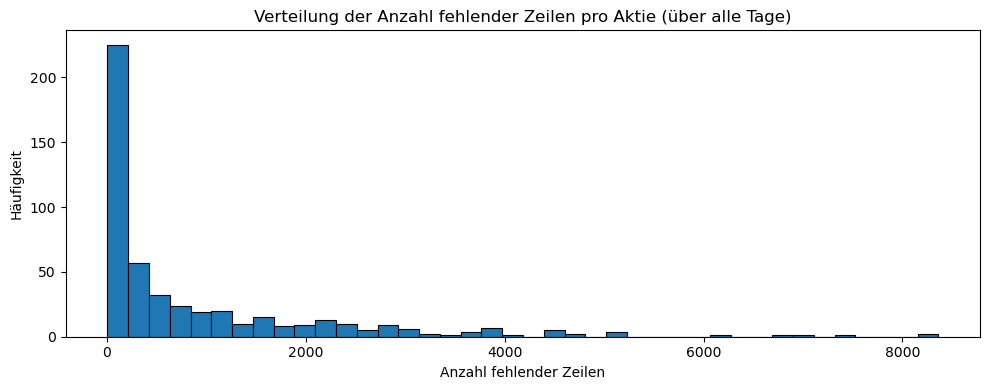

In [5]:
# Zelle 5: Aktien mit fehlenden Werten
missing = pp.analyze_missing_values(df, top_n=5, bins=40, show_plot=True)

Die meisten Aktien haben nur sehr wenige fehlende Datenpunkte, einige wenige jedoch deutlich mehr.

Nachdem festgestellt wurde, welche Aktien unvollständige Zeitreihen besitzen, wird nun untersucht, **wann** diese Datenlücken im jeweiligen Tagesverlauf auftreten. Diese Analyse hilft zu erkennen, ob die fehlenden Werte zufällig verteilt sind oder ob sie zu bestimmten Zeiten des Handelstages öfter vorkommen.

Ein grosses Auftreten zu bestimmten Uhrzeiten kann auf **technische Ursachen** (z. B. Marktpause) oder **marktbedingte Phasen geringer Aktivität** hindeuten.

Zur Analyse wird der Zeitstempel der Daten extrahiert und auf Minutenebene aggregiert. Anschließend wird gezählt, wie viele Werte zu jedem Zeitpunkt fehlen. Das Ergebnis wird in Form eines Liniendiagramms visualisiert, um die Häufigkeit fehlender Werte über den jeweiligen Tag hinweg zu untersuchen. Die Legende zum Diagramm wurde zur Übersichtlichkeit auskommentiert.

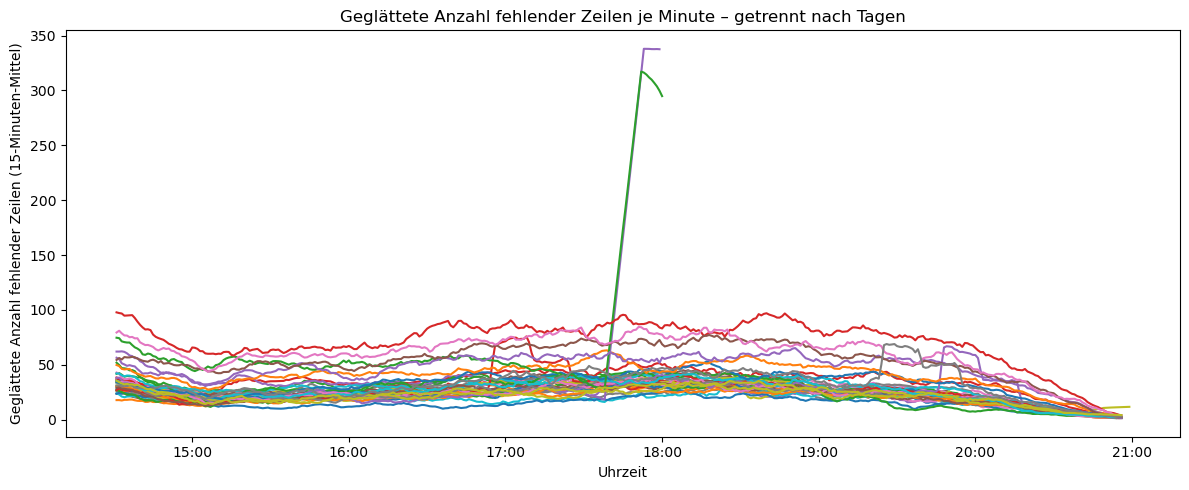

,rows_total,rows_missing,missing_%
2025-11-28,104233,11407,10.943751
2025-12-24,104234,14509,13.919642
2025-12-31,192660,23266,12.076196
2025-12-30,192660,20881,10.838264
2025-11-11,192763,11242,5.832032


In [6]:
# Zelle 6: Missing Coverage pro Tag
coverage = pp.analyze_missing_coverage(
    df,
    smoothing_window=15,
    show_plot=True,
    print_table=False
)
coverage.sort_values("rows_total").head(5)

Es ist zu erkennen, dass es zwei Tage gibt, die herausstechen [Referenz: Marktöffnungszeiten](https://www.nasdaqtrader.com/trader.aspx?id=calendar):
 - **28.11.2025**: Black Friday
 - **24.12.2025**: Weihnachten

An diesen beiden Tagen schloss der Markt früher. Diese beiden Daten werden aus dem Datensatz entfernt. Das ist korrekt, weil dann der Datensatz nicht komplett ist, jedoch ist das eine einfache Lösung. Der Aufwand würde extrem steigen, wenn man diese Daten nicht extrahieren würde. Nach der Entfernung werden

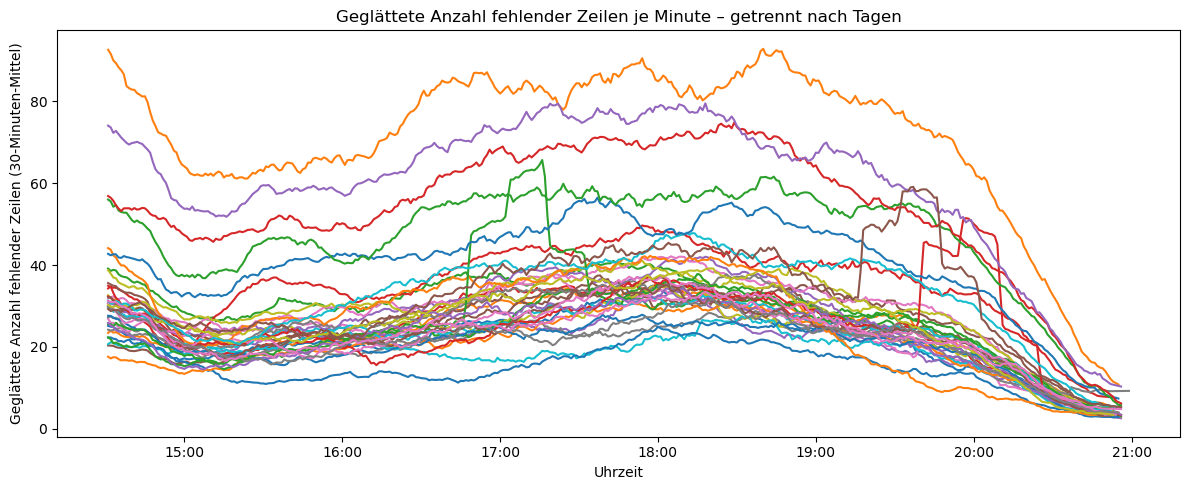

,rows_total,rows_missing,missing_%
2025-12-31,192660,23266,12.076196
2025-12-30,192660,20881,10.838264
2025-11-11,192763,11242,5.832032
2025-11-20,193144,7232,3.744357
2025-11-19,193149,9177,4.751254


In [7]:
# Zelle 7: Coverage nach Early-Close-Filter erneut prüfen
# Early-close Tage manuell entfernen
early_close_days = [
    pd.to_datetime("2025-11-28").date(),
    pd.to_datetime("2025-12-24").date(),
]

# Datum aus der datetime-Spalte ableiten und Maske bauen
dt = pd.to_datetime(df["datetime"], errors="coerce")
mask_keep = ~dt.dt.date.isin(early_close_days)

# Gefiltertes DataFrame
df_no_early_close = df.loc[mask_keep].copy()

# Coverage nach Entfernen der Early-close Days neu berechnen
coverage_no_early_close = pp.analyze_missing_coverage(
    df_no_early_close,
    smoothing_window=30,
    show_plot=True,
    print_table=False,
)
coverage_no_early_close.sort_values("rows_total").head(5)

Es ist ein Trend zu erkennen in den fehlenden Daten. Die Daten wurden auf den `datetime` aggregiert, um den Trend genauer untersuchen zu können, jedoch liegt dies nicht im Rahmen dieses Projekts. Der Trend ist im folgenden Histogramm besser zu erkennen:

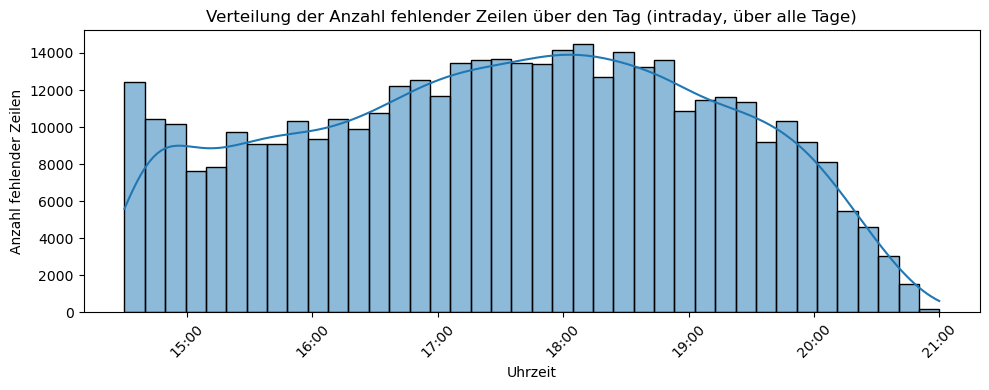

In [8]:
# Zelle 8: Aggregierte Visualisierung der Coverage
missing_time_df = pp.plot_intraday_missing_distribution(df_no_early_close, bins=40, kde=True)

Nun wird untersucht, ob und wie diese fehlenden Daten konsekutiv vorkommen. Diese Lücken sind ein Problem, falls sie zu gross werden. Es ist zu bemerken, dass die Zahlen hier nicht auf `datetime` aggregiert wurden, wie vorhin.

In der folgenden Analyse werden **Lücken (NaN-Werte)** in den Kursdaten aller Aktien untersucht. Die Funktion `analyze_nan_luecken_global()` sucht für jede Aktie zusammenhängende Bereiche mit fehlenden Werten und berechnet die Länge der Lücke in Minuten und die relative Preisänderung zwischen den Zeitpunkten davor und danach.

Gefundene Lücken insgesamt: 291121


,gap_len,rel_change
count,291121.000000,291121.000000
mean,2.409751,0.000001
std,0.998355,0.000962
min,2.000000,-0.020662
25%,2.000000,-0.000387
50%,2.000000,0.000000
75%,2.000000,0.000385
max,37.000000,0.051555


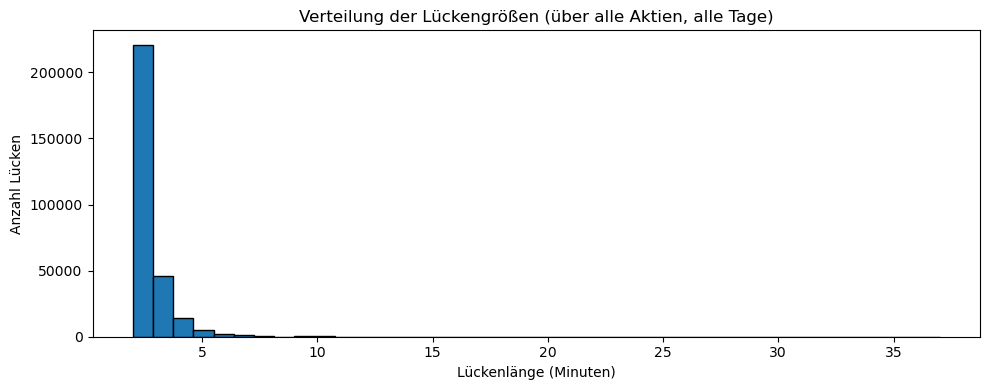

In [9]:
# Zelle 9: Überblick Zeitlücken (konsekutive NaNs)
nan_gaps_all = pp.analyze_nan_gaps_global(df_no_early_close)
print(f"Gefundene Lücken insgesamt: {len(nan_gaps_all)}")
display(nan_gaps_all.describe())
pp.plot_gap_length_hist(nan_gaps_all, bins=40, round_to_int=True)

Die statistische Auswertung zeigt, dass die meisten Lücken kurz sind und der Datensatz sollte deshalb kein Problem darstellen.

Das Histogramm visualisiert die Verteilung der Lückengrößen. Das Histogramm zeigt nicht besonders viel, aber den wesentlichen Punkt wird gut demonstriert: Der Großteil der Lücken ist sehr klein, längere Ausfälle sind sehr selten. Das deutet darauf hin, dass Datenunterbrechungen kurz und regelmäßig, aber nicht gravierend lang auftreten.

Probleme bereiten die grossen Lückengrössen aus, nicht die Kleinen. Nun werden folgende drei Tabellen ausgegeben:
 - Anzahl vorkommender Lücken pro Lückengrösse (in Minuten)
 - Anzahl Aktien mit mindestens einer Lücke > 5 Minuten
 - Anzahl Aktien mit mindestens einer Lücke > X Minuten (als Funktion von X)

In [10]:
# Zelle 10: Kernzahlen über Zeitlücken
gap_counts = pp.gap_len_counts(nan_gaps_all, min_gap=0, round_to_int=True)
print("Anzahl vorkommender Lücken pro Lückengröße (in Minuten):")
display(gap_counts.head(10))

long_gaps_tbl = pp.long_gap_summary(nan_gaps_all, threshold_min=5, round_to_int=True)
print(f"Anzahl Aktien mit mindestens einer Lücke > 5 Minuten: {len(long_gaps_tbl)}")
display(long_gaps_tbl.head(10))

gap_stats = pp.gap_stats_stocks_with_min_gap(nan_gaps_all, round_to_int=True)
print("Anzahl Aktien mit mindestens einer Lücke ≥ X Minuten:")
display(gap_stats)

Anzahl vorkommender Lücken pro Lückengröße (in Minuten):


,gap_len,count
0,2,220781
1,3,45620
2,4,13927
3,5,5353
4,6,2427
5,7,1240
6,8,710
7,9,365
8,10,243
9,11,144


Anzahl Aktien mit mindestens einer Lücke > 5 Minuten: 171


,symbol,n_gaps,max_gap
0,AIZ,441,37
1,NDSN,379,30
2,ERIE,476,24
3,XYZ,1,23
4,TPL,325,19
5,IEX,150,19
6,BR,117,18
7,CBOE,139,17
8,WAB,79,17
9,EPAM,46,17


Anzahl Aktien mit mindestens einer Lücke ≥ X Minuten:


,gap_length_min,n_stocks
0,1,494
1,2,494
2,3,494
3,4,303
4,5,215
5,6,171
6,7,134
7,8,101
8,9,77
9,10,65


Es ist zu interessant, dass jede Aktie mindestens eine Lücke von 3 Minuten hat. Um die letzte Tabelle zu visualisieren, wurde folgendes Diagramm erstellt:

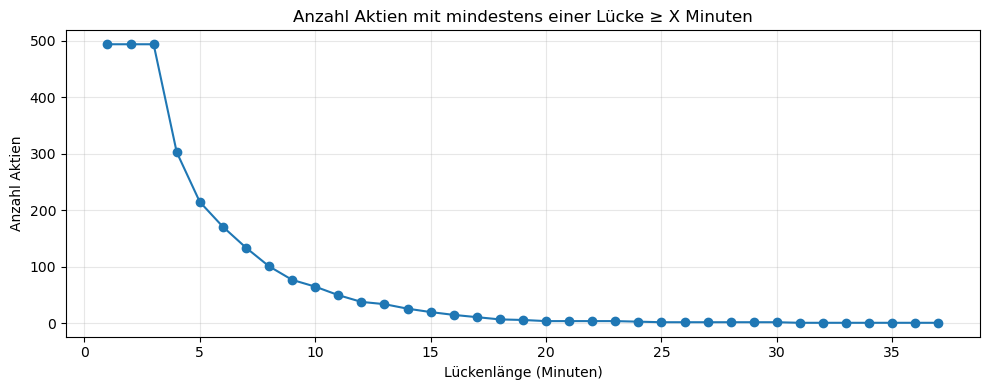

In [11]:
# Zelle 11: Aktien nach Zeitlückenlänge
pp.plot_stocks_vs_gap_threshold(gap_stats)

Dieses Diagramm sollte die Grundlage sein für die Entscheidung, welche Aktien aus dem Datensatz ausgeschlossen werden sollten. Da sie so "smooth" ist, wird es nach Bauchgefühl gemacht:

Es wurde entschieden, dass die Aktien mit Datenlücken, die **mindestens 16 Minuten** lang sind, entfernt werden.

In [12]:
# Zelle 12: Entfernung der Aktien mit zu grossen Zeitlücken
minute_threshold = 16

symbols_with_long_gaps = pp.find_symbols_with_long_gaps(
    nan_gaps_all,
    min_gap_len=minute_threshold,
)

print(f"Anzahl Aktien mit mindestens einer Lücke ≥ {minute_threshold} Minuten: {len(symbols_with_long_gaps)}")

df_clean = pp.drop_symbols(
    df_no_early_close,
    symbols_with_long_gaps,
    sort_by=["datetime"],
)

print(f"Verbleibende Aktien nach Filterung: {df_clean['symbol'].nunique()}")
print(f"Zeilen nach Filterung: {len(df_clean):,}")

Anzahl Aktien mit mindestens einer Lücke ≥ 16 Minuten: 15
Verbleibende Aktien nach Filterung: 479
Zeilen nach Filterung: 6,929,637


Die kleinen Datenlücken werden im folgenden Schritt bereinigt. Datenlücken werden gefüllt indem, sie interpoliert werden und in Edge-Cases wird von vorne/hinten aufgefüllt. Dazu wird die `close_filled` hinzugefügt, um die Daten nicht zu verfälschen. Anschliessend wird `close` entfernt.

In [13]:
# Zelle 13: Zeitlücken auffüllen
df_filled = pp.fill_close_gaps_per_symbol(
    df_clean,
    value_col="close",
    out_col="close_filled",
)

print("Fehlende Werte im Original (gefiltert):", df_clean["close"].isna().sum())
print("Fehlende Werte in close_filled:", df_filled["close_filled"].isna().sum())
df_filled = df_filled.drop(columns=["close"])

Fehlende Werte im Original (gefiltert): 340078
Fehlende Werte in close_filled: 0


## 3.3. Fehlende Daten (Zeilen)

 Da nun keine Datenlücken vorkommen, wird nun die Länge Daten pro Aktie analysiert.

In [14]:
# Zelle 14: Zeitreihenlängen
lengths = pp.symbol_lengths(df_filled)

print("Häufigste Längen:")
print(lengths.value_counts().sort_index())

Häufigste Längen:
14457      1
14462      1
14463      3
14464      2
14465      6
14466     11
14467    455
dtype: int64


Vereinzelte Aktien haben ausreissende Datenlängen. Diese sind problematisch. Zunächst wird untersucht, um welche Aktien es sich handelt.

In [15]:
# Zelle 15: Aktien mit falschen Zeitreihenlängen
expected_length = pp.expected_length_mode(lengths)
print(f"Erwartete Anzahl Zeilen pro Symbol: {expected_length}\n")

bad_symbols = pp.symbols_with_unexpected_length(lengths, expected_length)

if bad_symbols.empty:
    print("Alle Symbole haben die erwartete Länge – keine Entfernung nötig.")
    symbols_to_drop = []
else:
    print(f"{len(bad_symbols)} Symbole mit abweichender Länge gefunden:\n")
    symbols_to_drop = bad_symbols
    display(bad_symbols)

Erwartete Anzahl Zeilen pro Symbol: 14467

24 Symbole mit abweichender Länge gefunden:



symbol
FICO    14457
CMG     14462
JBL     14463
ROK     14463
CBRE    14463
ZTS     14464
ABT     14464
MTB     14465
CHD     14465
CNC     14465
MSI     14465
VLTO    14465
RL      14465
MRK     14466
FE      14466
CHRW    14466
CMI     14466
EMR     14466
WAT     14466
Q       14466
PPG     14466
CVX     14466
WSM     14466
DG      14466
dtype: int64

Es kann nicht erklärt werden, weshalb es hier Ausreisser gibt. Diese wenigen Aktien werden einfachheitshalber ausgeschlossen für einen guten Datensatz. Das kann man rechtfertigen, weil es so wenige sind und der Aufwand gross wäre.

In [16]:
# Zelle 16: Entfernen der Aktien mit falschen Zeitreihenlängen
n_before = df_filled["symbol"].nunique()

df_filled = pp.drop_symbols(
    df_filled,
    symbols_to_drop,
)

n_after = df_filled["symbol"].nunique()
print(f"Verbleibende Aktien: {n_after} (vorher: {n_before})")

Verbleibende Aktien: 479 (vorher: 479)


## 3.4. Duplikate
Bei weiterem arbeitem mit dem Dataframe wurde auffällig, dass es doppelte Einträge gibt. Diese sollten für einfache Computation entfernt werden.

In [17]:
# Zelle 17: Duplikatentfernung
df_clean, dup_rows = pp.drop_duplicate_rows(
    df_filled,
    subset=["datetime", "symbol"],
    keep="first",
    return_duplicates=True,
    sort_by=["symbol", "datetime"],
)
print(f"Anzahl doppelter Einträge: {len(dup_rows)}")

Anzahl doppelter Einträge: 1348


## 3.5. Validierung & Speicherung
Die Daten wurden nun bereinigt. Eine kurze Überprüfung zeigt, dass noch genug Daten vorhanden sind. Somit sind sowohl Menge und Qualität gesichert.

In [18]:
# Zelle 18: Entfernte Symbole
symbols_after = set(df_filled["symbol"].unique())
removed_symbols = symbols_beginning - symbols_after

print("Anzahl Aktien zu Beginn:", len(symbols_beginning))
print("Anzahl Aktien nach Bereinigung:", len(symbols_after), "\n")
print("Entfernte Aktien:", len(removed_symbols))
print(sorted(removed_symbols))

Anzahl Aktien zu Beginn: 509
Anzahl Aktien nach Bereinigung: 479 

Entfernte Aktien: 30
['AIZ', 'ARES', 'BR', 'CBOE', 'CRH', 'CRL', 'CVNA', 'DD', 'EPAM', 'ERIE', 'FI', 'FISV', 'FIX', 'IEX', 'IPG', 'JBHT', 'K', 'LKQ', 'MHK', 'MPWR', 'NDSN', 'NVR', 'SNDK', 'SOLS', 'STE', 'TPL', 'TT', 'UHS', 'WAB', 'XYZ']


In [19]:
# Zelle 19: Validierung der Datensäuberung
df_final = pp.validate_and_finalize_df(df_clean)

DataFrame validation passed
  - rows: 6928289
  - symbols: 479
  - start: 2025-11-07 14:30:00+00:00
  - end: 2026-01-05 21:00:00+00:00
  - filled_rows: None


Der Datensatz ist validiert und finalisiert. Die Anzahl verbleibenden Aktien ist genügend.

Zum Schluss werden die gesäuberten Daten noch gespeichert. Im Verlauf des Projektes wurde von CSV-Format zum Parquet-Format gewechselt, weil das Einlesen sehr lange dauerte. Dieses braucht auch weniger Speicherplatz.

In [20]:
# Zelle 20: Speicherung der gesäuberten Daten
io.save_preprocessed_data(
    df_final,
    data_dir="Daten",
    basename="market_data_cleaned",
)


[Preprocessed Data (to be saved)]
Shape: (6928289, 7)
Spalten: ['datetime', 'symbol', 'open', 'high', 'low', 'volume', 'close_filled']

Head:
                   datetime symbol        open        high         low  \
0 2025-11-07 14:30:00+00:00      A  146.520004  147.119995  145.729996   
1 2025-11-07 14:31:00+00:00      A         NaN         NaN         NaN   
2 2025-11-07 14:32:00+00:00      A  146.089996  146.089996  146.089996   
3 2025-11-07 14:33:00+00:00      A         NaN         NaN         NaN   
4 2025-11-07 14:34:00+00:00      A  146.049698  146.049698  146.049698   

    volume  close_filled  
0  13361.0    145.729996  
1      NaN    145.909996  
2    427.0    146.089996  
3      NaN    146.069847  
4   1387.0    146.049698  

Gespeichert als Daten\market_data_cleaned.parquet


Die Daten sind streng genommen nicht sauber. Die Spalte `close_filled` ist sauber, aber die anderen Spalten werden nicht gross betrachtet in der EDA und für die Features werden sie gar nicht beachtet.

Die Daten sind auch nicht im Format *tidy data*. Diese Entscheidung wurde getroffen, weil es Zeitreihen sind. Stattdessen sind sie nach `Symbol` und innerhalb von `Symbol` nach `datetime` sortiert. Dies wurde akzeptiert, weil es Zeitreihen sind.

---

<div style="display: flex; justify-content: space-between; margin-top: 30px;">
  <a href="02_Datensammlung.ipynb">
    <button style="background-color:#007acc;color:white;border:none;padding:8px 12px;border-radius:6px;cursor:pointer;">
      Zurück
    </button>
  </a>
  <a href="04_Explorative_Datenanalyse.ipynb">
    <button style="background-color:#007acc;color:white;border:none;padding:8px 12px;border-radius:6px;cursor:pointer;">
      Weiter
    </button>
  </a>
</div>
